# 05 · Comparaison des stratégies de transformation (A5)

Tâche A5 (issue #27), lot P4. On compare deux façons de préparer les variables avant la régression logistique, toutes choses égales par ailleurs : même modèle, mêmes variables V1, même découpage, mêmes métriques.

| | T1 (référence) | T2 |
|---|---|---|
| Numériques | médiane, standardisation | médiane, standardisation, et log1p des montants avant |
| Catégorielles | modalité la plus fréquente, one-hot | modalité la plus fréquente, one-hot avec regroupement des modalités rares (moins de 1 % de l'entraînement) |
| Valeurs manquantes | remplacées, sans trace | remplacées, et une colonne 0/1 par variable qui a des manquants dans l'entraînement |

Le protocole est celui de la PR #44 (C2) : entraînement de juin 2007 à décembre 2013, validation 2014, test 2015 jamais lu ici. La métrique de comparaison est la ROC-AUC de validation ; les six autres métriques de `evaluate()` servent à expliquer l'écart.

**État des dépendances au moment de l'écriture (25/11/2026).** Ni M1 (#10), ni M2 (#17), ni R2 (#14), ni D4 (#19), ni D1 (#9) ne sont fusionnés dans `dev`, et la PR #44 est encore ouverte. Le notebook se branche sur chacun d'eux dès qu'il existe, et utilise sinon un remplaçant local écrit d'après les docstrings de la PR #44 (`a5_transformations.py`, testé par `tests/notebooks/`). La cellule suivante affiche ce qui a réellement servi. **Sans données réelles, le notebook tourne sur des prêts factices, et ses chiffres ne disent rien des vrais prêts.**

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_curve

NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(REPO_ROOT / "notebooks"))
import a5_transformations as a5

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
SOURCES = {}  # ce qui a réellement servi : fonction réelle de src, ou remplaçant local
ECHECS = []   # tout ce qui n'a pas marché, gardé pour la conclusion

## 1. Protocole

`load_config()` (C2) lit `config/training.yaml`. Tant que la PR #44 n'est pas fusionnée, ce fichier n'existe pas dans `dev` : on prend alors la copie `PROTOCOL_V1` du module, recopiée de la PR. Si le vrai fichier existe et diffère sur une clé utilisée ici, on s'arrête, pour ne pas comparer des runs faits sous deux protocoles.

In [2]:
try:
    from src.training import load_config
    CFG = load_config()
    SOURCES["protocole"] = "config/training.yaml (load_config, C2)"
    differences = [k for k in a5.PROTOCOL_KEYS_USED if CFG.get(k) != a5.PROTOCOL_V1.get(k)]
    if differences:
        raise RuntimeError(
            f"Le protocole a changé depuis l'écriture du notebook sur : {differences}. "
            "Mettre à jour PROTOCOL_V1 ou vérifier que la comparaison reste valable."
        )
except (ImportError, FileNotFoundError):
    CFG = a5.PROTOCOL_V1
    SOURCES["protocole"] = "PROTOCOL_V1, copie locale de la PR #44 (C2 non fusionné)"

SEED = CFG["seed"]
SPLIT = CFG["split"]
TEST_START = pd.Timestamp(SPLIT["test"]["start"])
print("Protocole :", SOURCES["protocole"], "| version", CFG["protocol_version"], "| graine", SEED)
print("Entraînement", SPLIT["train"], "| validation", SPLIT["valid"], "| test jamais lu ici")

Protocole : PROTOCOL_V1, copie locale de la PR #44 (C2 non fusionné) | version v1 | graine 42
Entraînement {'start': '2007-06-01', 'end': '2013-12-31'} | validation {'start': '2014-01-01', 'end': '2014-12-31'} | test jamais lu ici


## 2. Données

Ordre de recherche, sans jamais lire de fichier `.env` :

1. `src.data.read_dev_frame()` (D1), qui renvoie les prêts de 2007 à 2014 ;
2. sinon `data/processed/dev.parquet`, écrit par l'ingestion (D1) ;
3. sinon des prêts factices (`make_synthetic_loans_a5`), avec un avertissement.

`test.parquet` n'est jamais ouvert. Juste après le chargement, on vérifie qu'aucun prêt n'est daté de 2015 ou après : le notebook s'arrête si c'est le cas.

In [3]:
DEV_PARQUET = REPO_ROOT / "data" / "processed" / "dev.parquet"
try:
    from src.data import read_dev_frame
except ImportError:
    read_dev_frame = None

if read_dev_frame is not None:
    raw = read_dev_frame()
    SOURCES["donnees"] = "read_dev_frame() (D1)"
elif DEV_PARQUET.exists():
    raw = pd.read_parquet(DEV_PARQUET)
    SOURCES["donnees"] = "data/processed/dev.parquet"
else:
    raw = a5.make_synthetic_loans_a5(n=40_000, seed=SEED)
    SOURCES["donnees"] = "prêts factices (make_synthetic_loans_a5) : aucune donnée réelle disponible"
DONNEES_REELLES = not SOURCES["donnees"].startswith("prêts factices")

dates = pd.to_datetime(raw[SPLIT["date_column"]])
assert (dates < TEST_START).all(), "Des prêts de 2015 ou après sont arrivés jusqu'ici : arrêt."
print(SOURCES["donnees"])
print(f"{len(raw):_} lignes brutes, de {dates.min():%Y-%m} à {dates.max():%Y-%m}".replace("_", " "))
if not DONNEES_REELLES:
    print("ATTENTION : données factices. Les écarts entre T1 et T2 ci-dessous ne valent que pour ce générateur.")

prêts factices (make_synthetic_loans_a5) : aucune donnée réelle disponible
40 000 lignes brutes, de 2007-06 à 2014-12
ATTENTION : données factices. Les écarts entre T1 et T2 ci-dessous ne valent que pour ce générateur.


## 3. Cleaning et découpage

On utilise `clean()` (M1) et `temporal_split()` (M1) dès qu'ils ont leur vrai corps. La PR #44 leur donne un corps factice qui écrit « corps factice » dans les logs : `a5.is_stub()` le détecte, et le notebook prend alors `clean_local()` et `temporal_split_local()`. Le remplaçant de `temporal_split()` applique les vraies dates du protocole (le corps factice coupe à 80 % des lignes, ce qui mélangerait 2013 et 2014).

In [4]:
def protocol_function(module, name, probe):
    # Renvoie la fonction réelle de src.training si elle existe et n'est plus factice, sinon None.
    # Une fonction réelle dont l'appel d'essai échoue n'est pas utilisée, et c'est noté dans ECHECS.
    try:
        fn = getattr(__import__(module, fromlist=[name]), name)
    except (ImportError, AttributeError):
        return None
    status = a5.probe_status(lambda: probe(fn))
    if status.startswith("erreur"):
        message = f"{module}.{name} existe mais son appel d'essai échoue ({status})"
        if DONNEES_REELLES:
            # Sur les vraies données, revenir en silence au remplaçant masquerait un problème.
            raise RuntimeError(message + " : à comprendre avant de comparer.")
        ECHECS.append(message + " : remplaçant local utilisé, sur données factices.")
    return fn if status == "reelle" else None

# Appel d'essai sur un échantillon des données chargées : avec les vraies données, il contient
# toutes les colonnes que le vrai clean() peut demander.
_probe_df = raw.sample(n=min(len(raw), 2000), random_state=SEED)
clean_fn = protocol_function("src.training", "clean", lambda f: f(_probe_df, cfg=CFG))
split_fn = protocol_function("src.training", "temporal_split", lambda f: f(a5.clean_local(_probe_df, CFG), CFG))

if clean_fn is not None:
    data = clean_fn(raw, cfg=CFG)
    SOURCES["clean"] = "src.training.clean (M1)"
else:
    data = a5.clean_local(raw, CFG)
    SOURCES["clean"] = "clean_local (M1 non livré : cible, périmètre, doublons seulement)"

if split_fn is not None:
    train, valid = split_fn(data, CFG)
    SOURCES["split"] = "src.training.temporal_split (M1)"
else:
    train, valid = a5.temporal_split_local(data, CFG)
    SOURCES["split"] = "temporal_split_local (dates du protocole)"

TARGET = CFG["target"]["column"]
date_col = SPLIT["date_column"]
assert pd.to_datetime(train[date_col]).max() <= pd.Timestamp(SPLIT["train"]["end"])
assert pd.to_datetime(valid[date_col]).min() >= pd.Timestamp(SPLIT["valid"]["start"])
assert pd.to_datetime(valid[date_col]).max() < TEST_START

resume = pd.DataFrame(
    {
        "prêts": [len(train), len(valid)],
        "taux de défaut": [train[TARGET].mean(), valid[TARGET].mean()],
        "de": [pd.to_datetime(train[date_col]).min(), pd.to_datetime(valid[date_col]).min()],
        "à": [pd.to_datetime(train[date_col]).max(), pd.to_datetime(valid[date_col]).max()],
    },
    index=["entraînement", "validation 2014"],
)
print(SOURCES["clean"], "|", SOURCES["split"])
resume

clean_local (M1 non livré : cible, périmètre, doublons seulement) | temporal_split_local (dates du protocole)


,prêts,taux de défaut,de,à
entraînement,30739,0.158366,2007-06-01,2013-12-01
validation 2014,9261,0.167584,2014-01-01,2014-12-01


## 4. Variables V1

V1 désigne les variables du contrat de données. Tant que le contrat v1 (D4, #19) n'existe pas, on prend la liste provisoire `V1_PROVISOIRE` du module : 16 colonnes Lending Club connues au moment de la demande, sans aucune colonne interdite (grade, sub_grade, int_rate, installment, funded_amnt_inv). Les montants qui passent au log1p dans T2 sont les variables numériques dont l'unité est en dollars, ou dont le nom figure dans `AMOUNT_COLUMNS` (pour ne pas perdre le log1p si le contrat écrit l'unité autrement). Le notebook s'arrête si aucun montant n'est reconnu.

In [5]:
try:
    from src.training import load_contract
    CONTRACT = load_contract()
except (ImportError, FileNotFoundError):
    CONTRACT = None
SPEC = a5.feature_spec(CONTRACT)
SOURCES["variables"] = SPEC.source

missing_cols = [c for c in SPEC.all if c not in train.columns]
if missing_cols:
    raise KeyError(f"Variables V1 absentes des données : {missing_cols}")

manquants = train[SPEC.all].isna().mean().rename("manquants (entraînement)")
table_v1 = pd.DataFrame(
    {
        "type": ["numérique"] * len(SPEC.numeric) + ["catégorielle"] * len(SPEC.categorical),
        "montant (log1p dans T2)": [c in SPEC.amounts for c in SPEC.all],
        "modalités": [train[c].nunique() if c in SPEC.categorical else None for c in SPEC.all],
    },
    index=SPEC.all,
).join(manquants)
print("Variables :", SPEC.source)
table_v1

Variables : V1 provisoire (A5)


,type,montant (log1p dans T2),modalités,manquants (entraînement)
loan_amnt,numérique,True,NaN,0.000000
annual_inc,numérique,True,NaN,0.000000
dti,numérique,False,NaN,0.000000
revol_bal,numérique,True,NaN,0.000000
revol_util,numérique,False,NaN,0.019454
fico_range_low,numérique,False,NaN,0.000000
open_acc,numérique,False,NaN,0.000000
total_acc,numérique,False,NaN,0.000000
delinq_2yrs,numérique,False,NaN,0.000000
inq_last_6mths,numérique,False,NaN,0.000000


## 5. Les deux transformations

Les deux `ColumnTransformer` sont construits par `a5.make_t1()` et `a5.make_t2()`. Ils sont ajustés **sur l'entraînement seulement**, à l'intérieur du pipeline : médianes, modalités les plus fréquentes, moyennes et écarts types, liste des modalités rares et liste des colonnes qui reçoivent un indicateur viennent toutes de 2007-2013. La validation 2014 ne fait que traverser le pipeline déjà ajusté.

Pourquoi chaque élément de T2 pourrait aider une régression logistique :

- **log1p des montants** : le revenu et le solde renouvelable sont très asymétriques. Sur l'échelle brute, quelques revenus très élevés pèsent sur le coefficient ; sur l'échelle log, une même hausse relative du revenu a le même effet, ce qui est souvent plus proche du risque réel.
- **Indicateurs de manquants** : quand l'absence d'une valeur est elle-même liée au risque (ancienneté d'emploi non déclarée, variable apparue en cours de période), la médiane efface cette information ; l'indicateur la garde.
- **Modalités rares** : une modalité vue quelques dizaines de fois donne un coefficient instable. Les regrouper réduit la variance, au prix d'un peu de détail.

Rien ne garantit que ces éléments aident : la régression logistique est régularisée (C = 1) et la standardisation atténue déjà une partie de l'asymétrie. C'est ce que la comparaison mesure.

In [6]:
if not SPEC.amounts:
    raise ValueError("Aucun montant reconnu dans les variables : T2 n'aurait pas de log1p.")
X_train_types = a5.to_sklearn_types(train[SPEC.all])
t1 = a5.make_t1(SPEC).fit(X_train_types)
t2 = a5.make_t2(SPEC).fit(X_train_types)
names_t2 = list(t2.get_feature_names_out())
indicateurs = [n.split("missingindicator_")[1] for n in names_t2 if n.startswith("manquants__")]
encodeur = t2.named_transformers_["categorielles"].named_steps["onehot"]
rares = {
    col: list(cats) for col, cats in zip(SPEC.categorical, encodeur.infrequent_categories_) if cats is not None
}
print(f"T1 : {len(t1.get_feature_names_out())} colonnes en sortie | T2 : {len(names_t2)} colonnes en sortie")
print("Indicateurs de manquants (T2) :", indicateurs or "aucun")
print("Montants passés au log1p (T2) :", SPEC.amounts or "aucun")
print("Modalités regroupées comme rares (T2) :")
for col, cats in rares.items():
    print(f"  {col} : {len(cats)} modalités -> {cats[:12]}{' ...' if len(cats) > 12 else ''}")

# Un indicateur n'a de sens que si l'absence a la même signification en 2014 qu'à
# l'entraînement. Une variable manquante seulement au début de la période marque l'époque
# du prêt, pas son risque : on le signale.
taux = pd.DataFrame(
    {
        "manquants entraînement": train[indicateurs].isna().mean(),
        "manquants validation 2014": valid[indicateurs].isna().mean(),
    }
)
for col, row in taux.iterrows():
    if row["manquants validation 2014"] < 0.25 * row["manquants entraînement"]:
        ECHECS.append(
            f"Réserve : l'indicateur de {col} est manquant pour {row['manquants entraînement']:.1%} de "
            f"l'entraînement et {row['manquants validation 2014']:.1%} de 2014. Il marque surtout la période "
            "du prêt (variable absente au début) et peut déplacer la calibration et le seuil."
        )
taux

T1 : 54 colonnes en sortie | T2 : 46 colonnes en sortie
Indicateurs de manquants (T2) : ['revol_util', 'mort_acc', 'emp_length']
Montants passés au log1p (T2) : ['loan_amnt', 'annual_inc', 'revol_bal']
Modalités regroupées comme rares (T2) :
  home_ownership : 2 modalités -> ['NONE', 'OTHER']
  purpose : 2 modalités -> ['educational', 'renewable_energy']
  addr_state : 10 modalités -> ['AK', 'IA', 'ID', 'ME', 'MS', 'ND', 'NE', 'SD', 'VT', 'WY']


,manquants entraînement,manquants validation 2014
revol_util,0.019454,0.02084
mort_acc,0.192329,0.00000
emp_length,0.066170,0.06522


## 6. Entraînement et évaluation sur 2014

Pour chaque transformation : pipeline (transformation puis `LogisticRegression(max_iter=2000, random_state=42)`) entraîné sur 2007-2013, probabilités de défaut sur 2014, seuil de décision choisi par la règle du protocole (profit réalisé maximal sur la validation, grille de 0,01 à 0,99), puis les sept métriques de `evaluate()`.

Comme pour POST /train, le seuil est choisi et évalué sur la même année 2014 : `realized_profit`, `precision`, `recall` et `acceptance_rate` sont donc un peu optimistes, pour les deux variantes de la même façon. La ROC-AUC et le score de Brier ne dépendent pas du seuil.

Chaque variante tourne dans un `try` : une erreur ou un avertissement de non-convergence est noté dans `ECHECS` au lieu d'arrêter le notebook.

In [7]:
def _probe_metrics(f):
    return f(np.array([0, 1, 0, 1]), np.array([0.1, 0.8, 0.3, 0.6]), 0.5, np.array([10.0, -50.0, 5.0, -20.0]))

evaluate_fn = protocol_function("src.training", "evaluate", _probe_metrics)
threshold_fn = protocol_function(
    "src.training", "choose_decision_threshold",
    lambda f: f(np.array([0, 1, 0]), np.array([0.2, 0.6, 0.3]), np.array([100.0, -500.0, 50.0]), cfg=CFG),
)
evaluate = evaluate_fn or a5.evaluate_local
choose_threshold = (lambda y, p, pr: threshold_fn(y, p, pr, cfg=CFG)) if threshold_fn else (
    lambda y, p, pr: a5.choose_threshold_local(y, p, pr, CFG)
)
SOURCES["evaluate"] = "src.training.evaluate (M2)" if evaluate_fn else "evaluate_local (M2 non livré)"
SOURCES["seuil"] = (
    "src.training.choose_decision_threshold (M2)" if threshold_fn else "choose_threshold_local (M2 non livré)"
)

X_train, y_train = train[SPEC.all], train[TARGET].to_numpy()
X_valid, y_valid = valid[SPEC.all], valid[TARGET].to_numpy()
profit_valid = (valid[CFG["business"]["paid_column"]] - valid[CFG["business"]["amount_column"]]).to_numpy(dtype=float)

RESULTATS, PROBAS, MODELES = {}, {}, {}
for name in ("T1", "T2"):
    started = time.perf_counter()
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            pipe = a5.make_pipeline(name, SPEC, SEED).fit(X_train, y_train)
        n_conv = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
        if n_conv:
            ECHECS.append(f"{name} : {n_conv} avertissement(s) de non-convergence de lbfgs.")
        proba = pipe.predict_proba(X_valid)[:, list(pipe.classes_).index(1)]
        threshold = choose_threshold(y_valid, proba, profit_valid)
        metrics = evaluate(y_valid, proba, threshold, profit_valid)
        RESULTATS[name] = {
            **metrics,
            "decision_threshold": threshold,
            "n_features_out": len(pipe.named_steps["transformation"].get_feature_names_out()),
            "convergence_warnings": n_conv,
            "duration_s": time.perf_counter() - started,
        }
        PROBAS[name], MODELES[name] = proba, pipe
    except Exception as exc:  # gardé pour la conclusion
        ECHECS.append(f"{name} : échec de l'entraînement ou de l'évaluation ({type(exc).__name__} : {exc}).")

print(SOURCES["evaluate"], "|", SOURCES["seuil"])
table = pd.DataFrame(RESULTATS).T
table.round({"roc_auc": 4, "pr_auc": 4, "brier": 4, "precision": 3, "recall": 3, "acceptance_rate": 3,
             "realized_profit": 0, "decision_threshold": 2, "duration_s": 1})

evaluate_local (M2 non livré) | choose_threshold_local (M2 non livré)


,roc_auc,pr_auc,brier,precision,recall,acceptance_rate,realized_profit,decision_threshold,n_features_out,convergence_warnings,duration_s
T1,0.6691,0.2775,0.1327,0.301,0.351,0.805,6011893.0,0.23,54.0,0.0,0.3
T2,0.6746,0.2850,0.1321,0.289,0.432,0.749,6133273.0,0.21,46.0,0.0,0.4


### Écart et incertitude

Un écart de ROC-AUC sur une seule année de validation peut venir du hasard de l'échantillon. On l'accompagne d'un intervalle bootstrap apparié à 95 % (300 tirages des prêts de 2014, les mêmes pour T1 et T2). Ce calcul n'est pas dans le protocole : c'est un ajout de ce notebook, qui sert à lire l'écart, pas à choisir quoi que ce soit sur le test.

In [8]:
if {"T1", "T2"} <= set(PROBAS):
    ECART = a5.paired_bootstrap_auc(y_valid, PROBAS["T1"], PROBAS["T2"], n_boot=300, seed=SEED)
    ecarts = (table.loc["T2", list(a5.METRIC_KEYS)] - table.loc["T1", list(a5.METRIC_KEYS)]).rename("T2 - T1")
    print(
        f"ROC-AUC T2 - T1 = {ECART['diff']:+.4f}, intervalle bootstrap à 95 % "
        f"[{ECART['low']:+.4f} ; {ECART['high']:+.4f}] ({ECART['n_boot']} tirages)"
    )
    display(ecarts.to_frame())
else:
    ECART = None
    print("Comparaison impossible : une variante a échoué (voir ECHECS).")

ROC-AUC T2 - T1 = +0.0055, intervalle bootstrap à 95 % [+0.0026 ; +0.0082] (300 tirages)


,T2 - T1
roc_auc,0.005466
pr_auc,0.007436
brier,-0.000574
precision,-0.012339
recall,0.081186
acceptance_rate,-0.055394
realized_profit,121380.830000


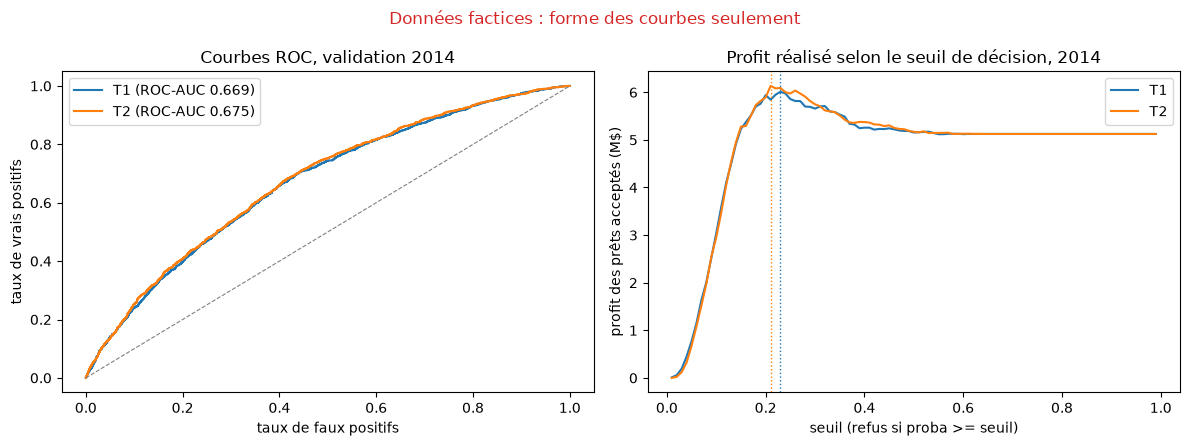

In [9]:
if {"T1", "T2"} <= set(PROBAS):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    grid = a5.threshold_grid(CFG)
    for name, color in (("T1", "tab:blue"), ("T2", "tab:orange")):
        fpr, tpr, _ = roc_curve(y_valid, PROBAS[name])
        axes[0].plot(fpr, tpr, color=color, label=f"{name} (ROC-AUC {RESULTATS[name]['roc_auc']:.3f})")
        profits = [profit_valid[PROBAS[name] < t].sum() / 1e6 for t in grid]
        axes[1].plot(grid, profits, color=color, label=name)
        axes[1].axvline(RESULTATS[name]["decision_threshold"], color=color, ls=":", lw=1)
    axes[0].plot([0, 1], [0, 1], color="grey", lw=0.8, ls="--")
    axes[0].set(title="Courbes ROC, validation 2014", xlabel="taux de faux positifs", ylabel="taux de vrais positifs")
    axes[1].set(title="Profit réalisé selon le seuil de décision, 2014", xlabel="seuil (refus si proba >= seuil)",
                ylabel="profit des prêts acceptés (M$)")
    for ax in axes:
        ax.legend()
    if not DONNEES_REELLES:
        fig.suptitle("Données factices : forme des courbes seulement", color="tab:red")
    plt.tight_layout()
    plt.show()

## 7. Runs MLflow

Un run par variante dans l'expérience `credit-exploration`, avec les quatre tags du protocole : `axe=transformation`, `variante=T1` ou `T2`, `lot=P4`, `protocole=v1` (construits par `comparison_tags()` de C2 quand il est fusionné, sinon par la même règle en local).

`log_comparison_run()` (R2, #14) n'est pas encore livré et sa signature (C3, #5) n'est pas posée : le notebook enregistre donc les runs avec l'API MLflow directement (`_log_comparison_run_local`), dans le même format (tags, paramètres, sept métriques). À la livraison de R2, il suffira de remplacer l'appel dans la boucle.

Où vont les runs :

- **données réelles** : serveur désigné par `MLFLOW_TRACKING_URI` (MLflow local du README, `http://127.0.0.1:5001`, lancé avec `uv run --env-file .env.experiment jupyter lab`) ;
- **données factices** : un MLflow jetable dans un dossier temporaire, jamais le serveur de l'équipe, pour ne pas mêler des runs factices aux vraies comparaisons.

Une variante en échec reçoit quand même un run, marqué `FAILED`. Chaque exécution ajoute deux runs : la synthèse (notebook 07) prend les plus récents pour un même tag `variante`.

In [10]:
import logging
import tempfile

# Messages sans intérêt ici (barre de progression absente, création de la base MLflow).
warnings.filterwarnings("ignore", message="IProgress not found")
import mlflow

logging.getLogger("mlflow").setLevel(logging.WARNING)

try:
    from src.training import comparison_tags
    SOURCES["tags"] = "src.training.comparison_tags (C2)"
except ImportError:
    def comparison_tags(axe, variante, lot, cfg=CFG):
        allowed = cfg["comparison_tags"]
        if axe not in allowed["axe"] or lot not in allowed["lot"] or not variante.strip():
            raise ValueError(f"Tag non permis : axe={axe}, variante={variante}, lot={lot}")
        return {"axe": axe, "variante": variante.strip(), "lot": lot, "protocole": str(cfg["protocol_version"])}
    SOURCES["tags"] = "comparison_tags local (même règle que C2)"

if DONNEES_REELLES and os.environ.get("MLFLOW_TRACKING_URI"):
    TRACKING_URI = os.environ["MLFLOW_TRACKING_URI"]
else:
    _tmp = Path(tempfile.mkdtemp(prefix="a5_mlflow_"))
    TRACKING_URI = f"sqlite:///{(_tmp / 'mlflow.db').as_posix()}"
    if DONNEES_REELLES:
        ECHECS.append("Données réelles mais MLFLOW_TRACKING_URI absent : runs écrits dans un MLflow temporaire.")
mlflow.set_tracking_uri(TRACKING_URI)
EXPERIMENT = mlflow.set_experiment("credit-exploration")
SOURCES["mlflow"] = "serveur MLFLOW_TRACKING_URI" if TRACKING_URI.startswith("http") else "MLflow temporaire (sqlite)"


def _log_comparison_run_local(name, tags, params, metrics, status="FINISHED"):
    with mlflow.start_run(run_name=f"A5-{name}", tags=tags) as run:
        mlflow.log_params(params)
        if metrics:
            mlflow.log_metrics({k: float(v) for k, v in metrics.items() if v == v})  # NaN exclus
        mlflow.set_tag("mlflow.note.content", f"Notebook 05, transformation {name}. Données : {SOURCES['donnees']}.")
    if status != "FINISHED":
        mlflow.tracking.MlflowClient().set_terminated(run.info.run_id, status=status)
    return run.info.run_id


RUN_IDS = {}
for name in ("T1", "T2"):
    params = {
        "transformation": name,
        "variables": "V1",
        "model": "logistic_regression",
        "model_params": '{"max_iter": 2000}',
        "seed": SEED,
        "protocol_version": CFG["protocol_version"],
        "train_period": f"{SPLIT['train']['start']} / {SPLIT['train']['end']}",
        "valid_period": f"{SPLIT['valid']['start']} / {SPLIT['valid']['end']}",
        "n_train": len(train),
        "n_valid": len(valid),
        "features_source": SPEC.source,
        "data_source": SOURCES["donnees"][:250],
        "rare_min_frequency": a5.RARE_MIN_FREQUENCY if name == "T2" else "sans objet",
        "decision_threshold_source": "profit maximal sur la validation 2014, métriques au seuil optimistes",
    }
    res = RESULTATS.get(name)
    if res is not None:
        params["decision_threshold"] = res["decision_threshold"]
        metrics = {k: res[k] for k in (*a5.METRIC_KEYS, "duration_s", "n_features_out", "convergence_warnings")}
        RUN_IDS[name] = _log_comparison_run_local(name, comparison_tags("transformation", name, "P4"), params, metrics)
    else:
        RUN_IDS[name] = _log_comparison_run_local(
            name, comparison_tags("transformation", name, "P4"), params, {}, status="FAILED"
        )

runs = mlflow.search_runs(
    experiment_ids=[EXPERIMENT.experiment_id],
    filter_string="tags.axe = 'transformation' and tags.lot = 'P4'",
)
print("MLflow :", SOURCES["mlflow"], "|", SOURCES["tags"])
runs[["tags.mlflow.runName", "status", "tags.axe", "tags.variante", "tags.lot", "tags.protocole",
      "metrics.roc_auc", "params.decision_threshold"]]

MLflow : MLflow temporaire (sqlite) | comparison_tags local (même règle que C2)


,tags.mlflow.runName,status,tags.axe,tags.variante,tags.lot,tags.protocole,metrics.roc_auc,params.decision_threshold
0,A5-T2,FINISHED,transformation,T2,P4,v1,0.674559,0.21
1,A5-T1,FINISHED,transformation,T1,P4,v1,0.669093,0.23


## 8. Raccord avec M2

La comparaison officielle reste faite avec T1 et T2 de ce notebook, même après la livraison de M2 : les deux variantes partagent alors exactement le même code, et seule la transformation change. Il faut en revanche vérifier que T1 ici est bien la T1 du projet. Quand M2 (#17) sera fusionné, `run_pipeline(df, {"transformation": "T1"})` donnera la ROC-AUC de la configuration de référence calculée par le vrai pipeline. La cellule suivante la compare à celle de T1 ici : avec les mêmes données, les mêmes variables et le même modèle, l'écart devrait être quasi nul ; au-delà de 0,001 (moins que l'effet minimal de la règle de choix), il signale une différence de mise en œuvre à comprendre avant de conclure. Si M2 met aussi T2 en place dans `build_pipeline()`, la même comparaison est faite pour T2. Tant que M2 n'est pas livré, la cellule le dit et ne fait rien.

In [11]:
# run_pipeline n'est utilisé que si build_pipeline n'est plus factice (M2 livré).
build_fn = protocol_function(
    "src.training", "build_pipeline", lambda f: f({"transformation": "T1"}, CONTRACT or {}, cfg=CFG)
)
run_pipeline_fn = None
if build_fn is not None:
    from src.training import run_pipeline as run_pipeline_fn
if run_pipeline_fn is None:
    SOURCES["raccord_M2"] = "non fait : build_pipeline a encore son corps factice ou n'existe pas (M2 non livré)"
else:
    for name in ("T1", "T2"):
        try:
            r = run_pipeline_fn(raw, {"transformation": name, "name": f"A5-{name}"}, cfg=CFG)
        except Exception as exc:
            ECHECS.append(f"Raccord M2, {name} : run_pipeline a échoué ({type(exc).__name__} : {exc}).")
            continue
        if name in RESULTATS:
            gap = r.metrics["roc_auc"] - RESULTATS[name]["roc_auc"]
            print(f"{name} : ROC-AUC M2 {r.metrics['roc_auc']:.4f}, notebook {RESULTATS[name]['roc_auc']:.4f}, écart {gap:+.4f}")
            if abs(gap) > 0.001:
                ECHECS.append(f"Raccord M2, {name} : écart de ROC-AUC de {gap:+.4f} entre M2 et le notebook.")
    SOURCES["raccord_M2"] = "fait avec src.training.run_pipeline (M2)"
print(SOURCES["raccord_M2"])

non fait : build_pipeline a encore son corps factice ou n'existe pas (M2 non livré)


## 9. Bilan de l'exécution

La cellule suivante récapitule ce qui a réellement servi (fonction réelle du projet ou remplaçant local), les échecs relevés et le constat chiffré. Le texte de la conclusion, plus bas, a été écrit à partir de ces sorties.

In [12]:
print("Ce qui a servi :")
for key, value in SOURCES.items():
    print(f"  {key:<12} {value}")
print("\nÉchecs et réserves relevés pendant l'exécution :")
for item in ECHECS or ["aucun"]:
    print("  -", item)
EFFET_MINIMAL = 0.002  # règle de choix proposée (section 10), fixée avant les vraies données
if ECART is not None:
    retenir_t2 = (
        ECART["low"] > 0
        and ECART["diff"] >= EFFET_MINIMAL
        and RESULTATS["T2"]["brier"] <= RESULTATS["T1"]["brier"]
    )
    print(
        f"\nConstat : ROC-AUC T1 {RESULTATS['T1']['roc_auc']:.4f}, T2 {RESULTATS['T2']['roc_auc']:.4f}, "
        f"écart {ECART['diff']:+.4f} [{ECART['low']:+.4f} ; {ECART['high']:+.4f}] ; "
        f"Brier T1 {RESULTATS['T1']['brier']:.4f}, T2 {RESULTATS['T2']['brier']:.4f}."
    )
    print("Règle de choix proposée :", "T2 retenue" if retenir_t2 else "T1 gardée")
print("\nDonnées réelles :", "oui" if DONNEES_REELLES else "NON, données factices : aucune conclusion sur les vrais prêts")

Ce qui a servi :
  protocole    PROTOCOL_V1, copie locale de la PR #44 (C2 non fusionné)
  donnees      prêts factices (make_synthetic_loans_a5) : aucune donnée réelle disponible
  clean        clean_local (M1 non livré : cible, périmètre, doublons seulement)
  split        temporal_split_local (dates du protocole)
  variables    V1 provisoire (A5)
  evaluate     evaluate_local (M2 non livré)
  seuil        choose_threshold_local (M2 non livré)
  tags         comparison_tags local (même règle que C2)
  mlflow       MLflow temporaire (sqlite)
  raccord_M2   non fait : build_pipeline a encore son corps factice ou n'existe pas (M2 non livré)

Échecs et réserves relevés pendant l'exécution :
  - Réserve : l'indicateur de mort_acc est manquant pour 19.2% de l'entraînement et 0.0% de 2014. Il marque surtout la période du prêt (variable absente au début) et peut déplacer la calibration et le seuil.

Constat : ROC-AUC T1 0.6691, T2 0.6746, écart +0.0055 [+0.0026 ; +0.0082] ; Brier T1 0.1327, T

## 10. Conclusion

**Exécution du 25/11/2026, sur 40 000 prêts factices.** Aucune donnée réelle n'était disponible (D1 non livré, pas de `dev.parquet`), et M1, M2, R2, C2 et D4 n'étaient pas fusionnés : la cellule Bilan liste les remplaçants locaux qui ont servi.

**Ce que cette exécution établit.**

- La chaîne complète tourne de zéro : prêts de 2007 à 2014 seulement (contrôle d'arrêt sur 2015), cible et périmètre du protocole, découpage 2007-06 à 2013-12 contre 2014, T1 et T2 ajustées sur l'entraînement seulement, seuil de décision par profit réalisé maximal, sept métriques de `evaluate()`.
- T2 fait ce qui est annoncé : trois indicateurs de manquants (les trois variables qui en ont à l'entraînement), log1p sur les trois montants en dollars, quatorze modalités regroupées comme rares, d'où 46 colonnes en sortie contre 54 pour T1.
- Deux runs MLflow, `A5-T1` et `A5-T2`, portent les tags `axe=transformation`, `variante`, `lot=P4` et `protocole=v1`, avec leurs paramètres et métriques. Ils ont été écrits dans un MLflow temporaire, puisque les données sont factices.
- Aucune erreur et aucun avertissement de non-convergence pendant l'exécution. La seule réserve relevée par le notebook porte sur l'indicateur de `mort_acc` (voir plus bas).

**Ce qu'elle n'établit pas.** T2 obtient une ROC-AUC de 0,6746 contre 0,6691 pour T1 (écart +0,0055, intervalle bootstrap à 95 % de +0,0026 à +0,0082). Ce gain était attendu par construction : le générateur de prêts factices fait dépendre le risque du logarithme du revenu et du montant, et rend l'absence d'ancienneté d'emploi plus fréquente chez les emprunteurs risqués. T2 retrouve simplement ce que le générateur y a mis. Une ablation faite à la relecture (hors notebook, mêmes données) le confirme : le log1p seul apporte +0,0036, les indicateurs seuls +0,0013, le regroupement des modalités rares seul +0,0003. Ce chiffre ne dit rien des vrais prêts Lending Club et ne doit pas être repris dans la synthèse (notebook 07).

**Échecs et réserves.**

- La comparaison sur les vraies données n'est pas faite : c'est l'objet de l'issue, et elle attend D1 (données), M2 (pipeline et métriques du projet, raccord de la section 8) et D4 (variables V1 du contrat). La liste V1 utilisée ici est provisoire.
- `log_comparison_run()` (R2) n'existe pas encore : les runs sont écrits avec l'API MLflow directement, dans le même format.
- Comme dans POST /train, le seuil de décision est choisi et mesuré sur la même année 2014 : les métriques au seuil (profit, précision, rappel, taux d'acceptation) sont optimistes, pour T1 comme pour T2. La ROC-AUC, qui décide, n'en dépend pas.
- Un seul découpage et une seule année de validation : l'intervalle bootstrap mesure le bruit d'échantillonnage de 2014, pas la variation d'une année à l'autre.
- L'indicateur de manquants de `mort_acc` marque l'époque du prêt plutôt que son risque : la variable manque pour 19,2 % de l'entraînement (tous les prêts d'avant 2010 dans ce générateur) et jamais en 2014. Il change peu la ROC-AUC, mais il peut déplacer la calibration et le seuil. Sur les vraies données, les variables apparues en cours de période (D3) poseront la même question : la cellule de la section 5 le signale automatiquement.

**Règle de choix proposée, à valider par l'équipe, fixée avant de voir les vraies données.** On retient T2 seulement si trois conditions sont réunies : la borne basse de l'intervalle bootstrap de l'écart de ROC-AUC est positive, l'écart vaut au moins 0,002 (avec des centaines de milliers de prêts, l'intervalle sera très étroit, et un écart minuscule mais « significatif » ne justifie pas une transformation de plus), et le score de Brier de T2 n'est pas plus mauvais. Sinon on garde T1, plus simple à expliquer et déjà configuration de référence. Les métriques au seuil servent à expliquer le résultat, pas à le renverser. La cellule Bilan applique cette règle ; sur les données factices, elle retient T2, ce qui ne vaut que pour le générateur.

**À faire après la livraison de D1, M2 et D4.** Relancer le notebook de zéro avec `uv run --env-file .env.experiment jupyter lab`, MLflow local démarré, vérifier que la cellule Bilan n'affiche plus de remplaçant, puis réécrire cette conclusion à partir de ses sorties.